# Halo preference versus stellar mass

Compare the best fit across starts with the fit from the centered initialization.
All four plots show raw $\Delta\chi^2=\chi^2_{\rm NFW}-\chi^2_{\rm Burkert}$.
Positive values favor Burkert and negative values favor NFW.

Darker points reach farther inward relative to the disk scale length.
In the inner-coverage views, filled markers have at least three measured radii within two disk scale lengths.
In the bound-contact views, diamonds indicate that at least one of the two plotted fits evaluated a parameter at a bound.
The three-point threshold measures inner sampling coverage.

Run the data-processing and sample-fitting notebooks first. The comparison uses saved attempts.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "models" / "masses.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.plotting import plot_halo_preference_vs_stellar_mass

INPUT_PATH = PROJECT_ROOT / "data/processed/selected_galaxy_rotation_curves.csv"
FIT_DIR = PROJECT_ROOT / "data/processed/halo_fits"
FIGURE_DIR = PROJECT_ROOT / "figures/halo_preference"
summary = pd.read_csv(FIT_DIR / "fit_summary.csv")
metadata = json.loads((FIT_DIR / "fit_config.json").read_text())
if hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest() != metadata["input_sha256"]:
    raise ValueError("Input changed since fitting. Rerun the sample-fitting notebook first.")
galaxies = pd.read_csv(INPUT_PATH.with_name("selected_galaxy_properties.csv"))
attempts = pd.read_csv(FIT_DIR / "fit_attempts.csv")

## Match stellar masses and inner coverage to model fits

In [2]:
if not (np.isfinite(galaxies.stellar_mass_msun) & galaxies.stellar_mass_msun.gt(0)).all():
    raise ValueError("Finite positive stellar masses are required")
comparison = galaxies.assign(log_stellar_mass=np.log10(galaxies.stellar_mass_msun))
models = ["nfw", "burkert"]
if attempts.duplicated(["galaxy", "model", "start"]).any():
    raise ValueError("Duplicate optimizer attempts")
if not attempts.evaluated_at_bound.isin([True, False]).all():
    raise ValueError("Missing or invalid bound-contact flags")
factors = metadata["fit"]["factors"]
start_factors = [(mass, concentration) for mass in factors for concentration in factors]
centered_start = start_factors.index((1, 1)) + 1

valid = attempts.loc[
    attempts.success & attempts.model.isin(models)
    & np.isfinite(attempts[["chi2", "log_m200", "concentration"]]).all(axis=1)
]
best = valid.sort_values(["chi2", "start"]).drop_duplicates(["galaxy", "model"])
centered = valid.loc[valid.start == centered_start]

for label, selected, chi2_columns, prefix in (
    ("Best of all starts", best, models, "best"),
    ("Centered start only", centered, [f"centered_chi2_{model}" for model in models], "centered"),
):
    chi2 = selected.pivot(index="galaxy", columns="model", values="chi2").reindex(columns=models)
    chi2.columns = chi2_columns
    contact = selected.pivot(index="galaxy", columns="model", values="evaluated_at_bound")
    contact = contact.reindex(columns=models).add_prefix(f"{prefix}_evaluated_at_bound_")
    comparison = comparison.join(chi2.join(contact), on="galaxy", validate="one_to_one")
    delta_column = "delta_chi2" if prefix == "best" else "centered_delta_chi2"
    comparison[delta_column] = comparison[chi2_columns[0]] - comparison[chi2_columns[1]]
    excluded = comparison.loc[comparison[delta_column].isna(), "galaxy"]
    print(f"{label}: {len(comparison) - len(excluded)} galaxies plotted")
    if not excluded.empty:
        print("Missing usable fit pair:", ", ".join(excluded))

saved_best = summary.loc[summary.status.eq("success") & summary.model.isin(models)]
actual_best = best.set_index(["galaxy", "model"]).chi2.sort_index()
expected_best = saved_best.set_index(["galaxy", "model"]).chi2.sort_index()
pd.testing.assert_series_equal(actual_best, expected_best)

Best of all starts: 108 galaxies plotted
Centered start only: 108 galaxies plotted


## Best of all starts (Bound contact)

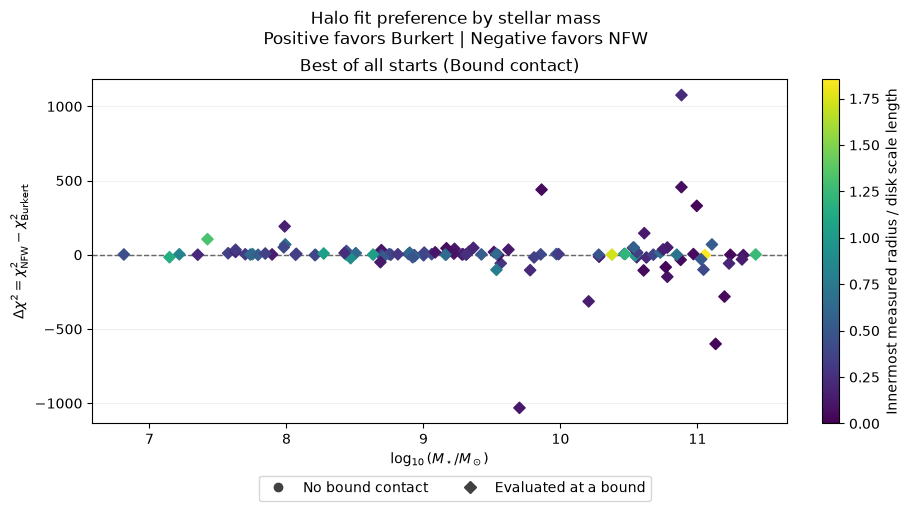

In [3]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=False, encoding="bounds")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass.pdf")
plt.show()
plt.close(fig)


## Best of all starts (Inner coverage)

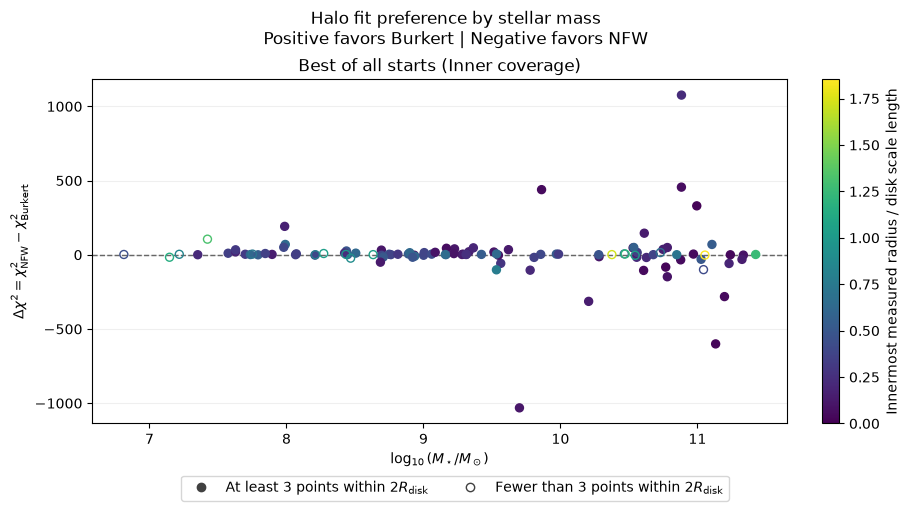

In [4]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=False, encoding="coverage")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_coverage.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_coverage.pdf")
plt.show()
plt.close(fig)


## Centered start only (Bound contact)

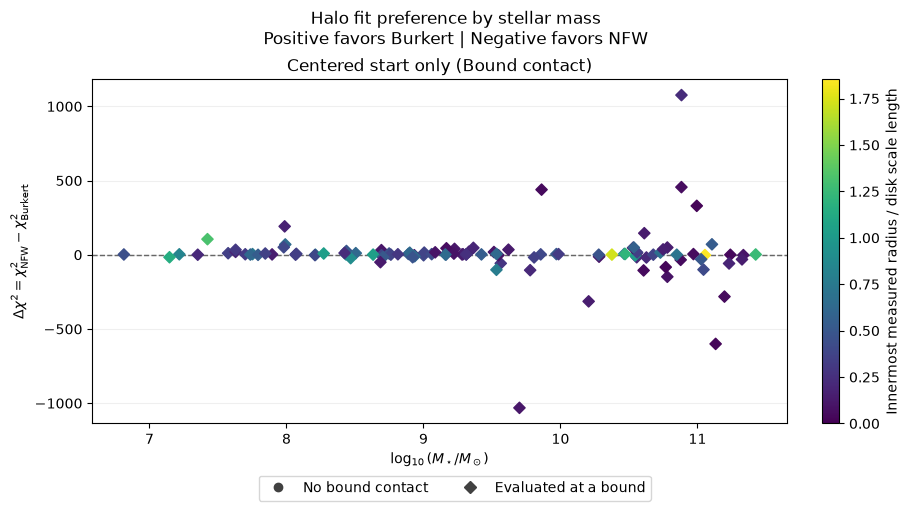

In [5]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=True, encoding="bounds")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered.pdf")
plt.show()
plt.close(fig)


## Centered start only (Inner coverage)

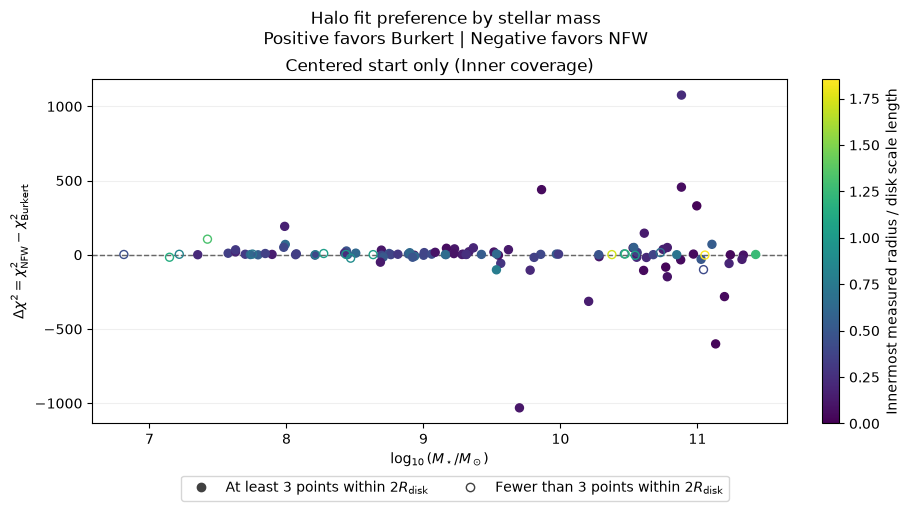

In [6]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=True, encoding="coverage")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered_coverage.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered_coverage.pdf")
plt.show()
plt.close(fig)


In [7]:
comparison.to_csv(FIT_DIR / "stellar_mass_halo_preference.csv", index=False)